In [1]:
# 1. IMPORT LIBRARIES
import pandas as pd
import re
import nltk

from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

# Download NLTK resources (run once)
nltk.download('punkt_tab')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\trbha\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\trbha\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [2]:
# Load the CSV file 
df = pd.read_csv("cw_data.csv", header=None)
df.columns = ["text", "label"]

# Verify class distribution
print(df['label'].value_counts())

label
payment_issue              33
shipping_delay             29
notification_settings      24
delete_account             23
subscription_management    23
update_email               23
data_privacy               22
order_tracking             22
billing_history            21
account_recovery           21
refund_request             21
reset_password             20
login_issue                16
two_factor_auth            10
Name: count, dtype: int64


In [3]:
# 3. DOMAIN-SPECIFIC CLEANING
abbrev_dict = {
    "pls": "please",
    "acct": "account",
    "pw": "password",
    "cant": "cannot",
    "u": "you",
    "msg": "message"
}

def clean_abbreviations(text):
    tokens = text.split()
    tokens = [abbrev_dict.get(word.lower(), word) for word in tokens]
    return " ".join(tokens)

In [4]:
# 4. TEXT PREPROCESSING
lemmatizer = WordNetLemmatizer()

def clean_text_advanced(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = clean_abbreviations(text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(tokens)

df['clean_text'] = df['text'].apply(clean_text_advanced)

In [5]:
# 5. FEATURE ENGINEERING (TF-IDF)
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    sublinear_tf=True,
    stop_words='english'
)

In [6]:
# 6. TRAIN-TEST SPLIT
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['clean_text'],
    df['label'],
    test_size=0.2,
    stratify=df['label'],
    random_state=42
)

In [7]:
# Vectorize after split to prevent data leakage
X_train = tfidf_vectorizer.fit_transform(X_train_text)
X_test = tfidf_vectorizer.transform(X_test_text)

In [8]:
# 7. MODEL + GRIDSEARCH
lr = LogisticRegression(class_weight='balanced', max_iter=1000)

param_grid = {
    'C': [0.01, 0.1, 1, 10]
}

grid_lr = GridSearchCV(
    lr,
    param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

best_lr = grid_lr.best_estimator_

print("Best Parameters:", grid_lr.best_params_)

Best Parameters: {'C': 10}


In [9]:
# 8. EVALUATION
y_pred = best_lr.predict(X_test)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

f1 = f1_score(y_test, y_pred, average='macro')
print("Macro F1 Score:", f1)


Classification Report:

                         precision    recall  f1-score   support

       account_recovery       0.67      1.00      0.80         4
        billing_history       1.00      0.75      0.86         4
           data_privacy       1.00      0.75      0.86         4
         delete_account       1.00      0.80      0.89         5
            login_issue       1.00      1.00      1.00         3
  notification_settings       1.00      1.00      1.00         5
         order_tracking       0.80      1.00      0.89         4
          payment_issue       1.00      1.00      1.00         7
         refund_request       1.00      0.75      0.86         4
         reset_password       1.00      1.00      1.00         4
         shipping_delay       1.00      1.00      1.00         6
subscription_management       0.71      1.00      0.83         5
        two_factor_auth       1.00      0.50      0.67         2
           update_email       1.00      1.00      1.00         5

<Figure size 1200x1000 with 0 Axes>

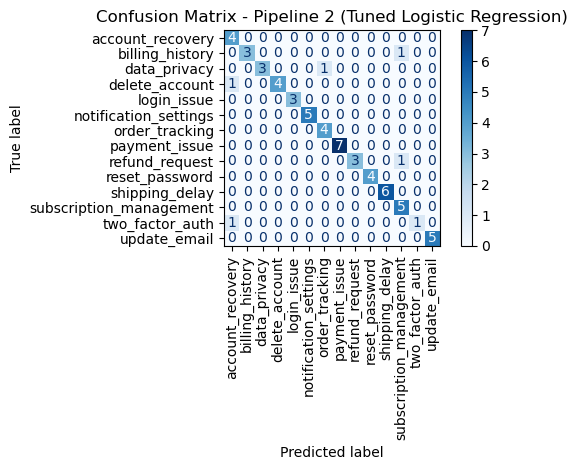

In [10]:
#9. CONFUSION MATRIX

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix FIRST
cm = confusion_matrix(y_test, y_pred, labels=best_lr.classes_)

# Then plot
plt.figure(figsize=(12,10))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_lr.classes_)
disp.plot(cmap='Blues', xticks_rotation=90)

plt.title("Confusion Matrix - Pipeline 2 (Tuned Logistic Regression)")
plt.tight_layout()

plt.show()

In [11]:

errors_df = pd.DataFrame({
    'text': df.loc[y_test.index, 'text'],
    'actual': y_test,
    'predicted': y_pred
})

errors_df = errors_df[errors_df['actual'] != errors_df['predicted']]
errors_df.sample(5)

,text,actual,predicted
112,all subscription payments in history?,billing_history,subscription_management
131,refund after subscription cancelled possible?,refund_request,subscription_management
97,who has access to my info internally?,data_privacy,order_tracking
132,error deleting acct wat wrong?,delete_account,account_recovery
262,I lost access to my 2FA device — can I recover...,two_factor_auth,account_recovery


In [12]:
# SECOND MODEL: NAIVE BAYES

from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()

param_grid_nb = {
    'alpha': [0.1, 0.5, 1.0]
}

grid_nb = GridSearchCV(
    nb,
    param_grid_nb,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1
)

# Train
grid_nb.fit(X_train, y_train)

# Best model
best_nb = grid_nb.best_estimator_

print("Best NB Parameters:", grid_nb.best_params_)

# Predict
y_pred_nb = best_nb.predict(X_test)

# Evaluate
from sklearn.metrics import f1_score

f1_nb = f1_score(y_test, y_pred_nb, average='macro')
print("Naive Bayes Macro F1:", f1_nb)

Best NB Parameters: {'alpha': 0.1}
Naive Bayes Macro F1: 0.832446918161204
